## Columbia University
### ECBM E4040 Neural Networks and Deep Learning.
<font color="red"><strong>Fall 2026.</strong></font>

# Assignment 1, Task 3: Multilayer Perceptron (MLP)
This is the third part of the assignment. You will get to implement MLP using tensorflow

## Setup

Run this cell first. Colab gives every notebook its own runtime, so it has to run
in every task notebook, not just once.

It needs a GitHub token: add a secret called `GITHUB_TOKEN` from the key icon in
the left sidebar, and turn on notebook access for it.

In [5]:
# =====================================================================
# SETUP - run this first, every time you open this notebook.
# Colab gives every notebook its own runtime, so it must run in each one.
# Safe to re-run. Uses whatever TensorFlow/NumPy Colab ships.

# Make sure to add a "GITHUB_TOKEN" in your secrets (the key on the LHS of colab), this is a personal access token
# =====================================================================

# ---------------------------------------------------------------------
#  EDIT THESE THREE
# ---------------------------------------------------------------------
REPO = "your-username/e4040-2026fall-assign1-UNI"  # "your-username/e4040-2026fall-assign1-UNI"

BRANCH = "main" #  Probably "main".

FOLDER = "assignment1"  #  Folder inside the repo holding the notebooks.
# ---------------------------------------------------------------------
#  Nothing else in this cell needs changing.
# --------------------------------------------------------------------

CLONE_TO = "/content/e4040"
DRIVE_CACHE = "/content/drive/MyDrive/e4040-data/medmnist"

import os
import shutil
import subprocess
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def run(cmd, redact=None, **kw):
    """Run a command, masking `redact` out of any error text."""
    def hide(t):
        return t.replace(redact, "***") if (redact and t) else t

    r = subprocess.run(cmd, capture_output=True, text=True, **kw)
    if r.returncode:
        raise RuntimeError(f"{hide(' '.join(cmd))} failed:\n{hide(r.stderr).strip()}")
    return r.stdout


if IN_COLAB:
    # Cache the dataset in Drive.
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_CACHE, exist_ok=True)

    link = os.path.expanduser("~/.medmnist")
    if os.path.isdir(link) and not os.path.islink(link):
        shutil.rmtree(link)     # stale local copy
    elif os.path.lexists(link):
        os.remove(link)
    os.symlink(DRIVE_CACHE, link)

    # Clone only FOLDER. Changing FOLDER re-clones.
    target = os.path.join(CLONE_TO, FOLDER)
    if not os.path.isdir(target):
        from google.colab import userdata
        if os.path.isdir(CLONE_TO):
            print(f"'{FOLDER}' not in existing clone - re-cloning.")
            shutil.rmtree(CLONE_TO)

        try:
            token = (userdata.get("GITHUB_TOKEN") or "").strip()
        except userdata.SecretNotFoundError:
            raise RuntimeError(
                "Add a GITHUB_TOKEN secret (key icon, left sidebar).") from None
        except userdata.NotebookAccessError:
            raise RuntimeError(
                "Turn on notebook access for the GITHUB_TOKEN secret.") from None
        if not token:
            raise RuntimeError("The GITHUB_TOKEN secret is empty.")

        url = f"https://{token}@github.com/{REPO}.git"
        try:
            run(["git", "clone", "--depth", "1", "--single-branch", "--branch",
                 BRANCH, "--filter=blob:none", "--sparse", url, CLONE_TO], redact=token)
            run(["git", "sparse-checkout", "set", FOLDER], cwd=CLONE_TO, redact=token)
            run(["git", "remote", "set-url", "origin",
                 f"https://github.com/{REPO}.git"], cwd=CLONE_TO, redact=token)
        finally:
            del token, url

        if not os.path.isdir(target):
            raise RuntimeError(f"'{FOLDER}' not found on branch '{BRANCH}'.")

    os.chdir(target)

# Make utils/ importable.
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

missing = [p for p in ("utils/layer_funcs.py", "utils/layer_utils.py",
                       "utils/classifiers/twolayernet.py") if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(
        f"In '{os.getcwd()}' but missing:\n  " + "\n  ".join(missing)
        + f"\n\nCheck FOLDER ('{FOLDER}') exists on branch '{BRANCH}'.")

import numpy as np
import tensorflow as tf

cache = os.path.join(os.path.expanduser("~/.medmnist"), "pathmnist.npz")
print(f"dir    : {os.getcwd()}")
print(f"source : {BRANCH} / {FOLDER}")
print(f"python : {sys.version.split()[0]}   numpy: {np.__version__}   tf: {tf.__version__}")
print(f"gpu    : {bool(tf.config.list_physical_devices('GPU'))}")
print(f"data   : {str(os.path.getsize(cache) // 1024**2) + ' MB cached' if os.path.isfile(cache) else 'downloads on first run (~196 MB)'}")


dir    : c:\Users\dexfo\OneDrive\Documents\DexterFiles\Columbia\Neurel Networks\Assignment2
source : main / assignment1
python : 3.11.9   numpy: 2.4.6   tf: 2.21.0
gpu    : False
data   : 196 MB cached


In [6]:
# Import modules
from __future__ import print_function
import tensorflow as tf
import numpy as np
import time
import os
import matplotlib.pyplot as plt
import pickle
import requests

# Plot configurations
%matplotlib inline

# Auto-reload edited files in utils/. Colab's IPython imports `imp`, which
# Python 3.12 removed, so provide it.
import importlib
import sys
import types

if "imp" not in sys.modules:
    imp_shim = types.ModuleType("imp")
    imp_shim.reload = importlib.reload
    sys.modules["imp"] = imp_shim

try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception as exc:
    print("autoreload unavailable:", exc)
    print("After editing files in utils/, restart the runtime and re-run.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load Data

In [7]:
# We use PathMNIST (colon pathology, 9 classes, RGB 28x28x3).
# MedMNIST distributes each dataset as a single .npz file. We load it directly
# with NumPy so that ONLY TensorFlow/NumPy are needed -- the `medmnist` PyPI
# package is intentionally avoided because it depends on PyTorch.
PATHMNIST_URL = "https://zenodo.org/records/10519652/files/pathmnist.npz?download=1"
data_dir = os.path.expanduser("~/.medmnist")
os.makedirs(data_dir, exist_ok=True)
npz_path = os.path.join(data_dir, "pathmnist.npz")

# Download once (~200 MB) on first run; reused afterwards (shared across all
# three tasks if you've already run one, since it's cached to the same path).
# Zenodo (the file host) has had intermittent slowdowns/timeouts under load,
# so we retry with backoff rather than failing on the first hiccup.
def _download_with_retry(url, dest_path, max_retries=5, backoff_seconds=10):
    import time as _time
    for attempt in range(1, max_retries + 1):
        try:
            print("Downloading PathMNIST (attempt {}/{}) ...".format(attempt, max_retries))
            response = requests.get(url, stream=True, timeout=60)
            response.raise_for_status()
            with open(dest_path, 'wb') as f:
                for chunk in response.iter_content(chunk_size=8192):
                    f.write(chunk)
            return
        except requests.exceptions.RequestException as e:
            print("Attempt {} failed: {}".format(attempt, e))
            if os.path.exists(dest_path):
                os.remove(dest_path)
            if attempt < max_retries:
                wait = backoff_seconds * attempt
                print("Retrying in {} seconds...".format(wait))
                _time.sleep(wait)
            else:
                raise RuntimeError(
                    "Failed to download PathMNIST after {} attempts. "
                    "Zenodo may be temporarily overloaded -- try again shortly.".format(max_retries)
                )

if not os.path.exists(npz_path):
    _download_with_retry(PATHMNIST_URL, npz_path)

# The .npz stores each split as {split}_images / {split}_labels.
with np.load(npz_path) as npz:
    X_train_raw, y_train = npz['train_images'], npz['train_labels'].flatten()
    X_val_raw,   y_val   = npz['val_images'],   npz['val_labels'].flatten()
    X_test_raw,  y_test  = npz['test_images'],  npz['test_labels'].flatten()

# MedMNIST images are RGB (28x28x3), so each image flattens to D = 28*28*3 = 2352.
X_train = X_train_raw.reshape((X_train_raw.shape[0], -1))
X_val = X_val_raw.reshape((X_val_raw.shape[0], -1))
X_test = X_test_raw.reshape((X_test_raw.shape[0], -1))

# Number of classes for the softmax output layer (9 for PathMNIST).
num_classes = int(np.max(y_train)) + 1

# Data organizations (PathMNIST native splits):
# Train data:      89,996 samples
# Validation data: 10,004 samples
# Test data:       7,180 samples
# Development data (for gradient check): 100 random samples from the training set
num_dev = 100
mask = np.random.choice(X_train.shape[0], num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# Preprocessing: subtract the mean value across every dimension for training data
mean_image = np.mean(X_train, axis=0)

X_train = X_train.astype(np.float32) - mean_image.astype(np.float32)
X_val = X_val.astype(np.float32) - mean_image
X_test = X_test.astype(np.float32) - mean_image
X_dev = X_dev.astype(np.float32) - mean_image

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)
print('Number of classes: ', num_classes)
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)
print('Development data shape:', X_dev.shape)
print('Development data shape', y_dev.shape)

(89996, 2352) (10004, 2352) (7180, 2352) (100, 2352)
Number of classes:  9
Train data shape:  (89996, 2352)
Train labels shape:  (89996,)
Validation data shape:  (10004, 2352)
Validation labels shape:  (10004,)
Test data shape:  (7180, 2352)
Test labels shape:  (7180,)
Development data shape: (100, 2352)
Development data shape (100,)


## Part 1: Tensorflow MLP (10%)
In this part, you will use tensorflow modules to implement an MLP. We provide a demo of a two-layer net, the style of is referenced from https://www.tensorflow.org/guide/keras and https://www.tensorflow.org/guide/eager. 

You need to implement a MLP with 4 layers in a similar style.

### Demo: Two-layer MLP in Tensorflow

In [8]:
## Demo: Two-layer net in tensorflow (eager execution mode)
hidden_dim = 300
reg_tf = tf.constant(0.01)

# define a tf.keras.Model class
class Model(tf.keras.Model):
    def __init__(self):
        super(Model, self).__init__()
        self.W1 = tf.Variable(1e-2*np.random.rand(X_train.shape[1], hidden_dim).astype('float32'))
        self.b1 = tf.Variable(np.zeros((hidden_dim,)).astype('float32'))
        self.W2 = tf.Variable(1e-2*np.random.rand(hidden_dim, num_classes).astype('float32'))
        self.b2 = tf.Variable(np.zeros((num_classes,)).astype('float32'))
    def call(self, inputs):
        """Run the model."""
        h1 = tf.nn.relu(tf.matmul(inputs, self.W1) + self.b1)
        out = tf.matmul(h1, self.W2) + self.b2
        return out

# Define and calculate loss function (Note that in eager execution, loss must be in a function)
def loss(model, inputs, targets, reg = tf.constant(0.01)):
    out = model(inputs)
    cross_entropy = tf.nn.softmax_cross_entropy_with_logits(logits= out, labels=tf.one_hot(targets, num_classes))    
    L2_loss = tf.nn.l2_loss(model.W1) + tf.nn.l2_loss(model.W2)
    return tf.reduce_mean(cross_entropy) + reg * L2_loss

# calculate gradients for all variables using tf.GradientTape
def grad(model, inputs, targets, reg = tf.constant(0.01)):
    with tf.GradientTape() as tape:
        loss_value = loss(model, inputs, targets, reg=reg)
    return tape.gradient(loss_value, [model.W1, model.b1, model.W2, model.b2])

# calculate classification accuracy
def eval_acc(model, inputs, targets):
    correct_prediction = tf.equal(targets, tf.cast(tf.argmax(model(inputs),1), tf.uint8))
    accuracy = tf.reduce_mean(tf.cast(correct_prediction, tf.float32))
    return accuracy

num_train = X_train.shape[0]
batch_size = 500
num_batch = num_train//batch_size
num_epochs = 15
model = Model()
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)

for e in range(num_epochs):
    for i in range(num_batch):
        batch_xs, batch_ys = X_train[i*batch_size:(i+1)*batch_size], y_train[i*batch_size:(i+1)*batch_size]
        x_tf = tf.Variable(batch_xs, dtype = tf.float32)
        y_tf = tf.Variable(batch_ys, dtype = tf.uint8)
        
        grads = grad(model, x_tf, y_tf, reg_tf)
        #optimization based on calculated gradients 
        optimizer.apply_gradients(zip(grads, [model.W1, model.b1, model.W2, model.b2]))

    x_tf = tf.Variable(X_val, dtype = tf.float32)
    y_tf = tf.Variable(y_val, dtype = tf.uint8)
    accuracy = eval_acc(model, x_tf, y_tf)
    val_acc = accuracy.numpy()
    print('epoch {}: valid acc = {}'.format(e+1, val_acc))

x_tf = tf.Variable(X_test, dtype = tf.float32)
y_tf = tf.Variable(y_test, dtype = tf.uint8)
accuracy = eval_acc(model, x_tf, y_tf)
test_acc = accuracy.numpy()
print('test acc = {}'.format(test_acc))

epoch 1: valid acc = 0.338764488697052
epoch 2: valid acc = 0.3723510503768921
epoch 3: valid acc = 0.3794482350349426
epoch 4: valid acc = 0.37744900584220886
epoch 5: valid acc = 0.42223110795021057
epoch 6: valid acc = 0.43672531843185425
epoch 7: valid acc = 0.49630147218704224
epoch 8: valid acc = 0.5172930955886841
epoch 9: valid acc = 0.5339863896369934
epoch 10: valid acc = 0.5569772124290466
epoch 11: valid acc = 0.5698720216751099
epoch 12: valid acc = 0.5758696794509888
epoch 13: valid acc = 0.5756697058677673
epoch 14: valid acc = 0.5751699209213257
epoch 15: valid acc = 0.5778688788414001
test acc = 0.5589136481285095


### Create Deeper Network

<span style="color:red"><strong>TODO</strong></span>: Create your MLP in tensorflow. Since you are going to create a deeper neural network, it is recommended to use "list" to store your network parameters (weights and bias). Consider using a loop to create your MLP network.

<span style="color:red"><strong>HINT</strong></span>: Copy the code above and make necessary changes in model definition.

In [9]:
# Create you MLP using TensorFlow functions.

############################################################################
#                         START OF YOUR CODE                               #
############################################################################

hidden_dims = [300, 200, 100]
reg_tf = tf.constant(0.01)

class MLPModel(tf.keras.Model):
    def __init__(self):
        super(MLPModel, self).__init__()
        dims = [X_train.shape[1]] + hidden_dims + [num_classes]
        self.Ws = []
        self.bs = []
        for i in range(len(dims) - 1):
            self.Ws.append(tf.Variable(1e-2*np.random.rand(dims[i], dims[i+1]).astype('float32')))
            self.bs.append(tf.Variable(np.zeros((dims[i+1],)).astype('float32')))
    def call(self, inputs):
        h = inputs
        for W, b in zip(self.Ws[:-1], self.bs[:-1]):
            h = tf.nn.relu(tf.matmul(h, W) + b)
        return tf.matmul(h, self.Ws[-1]) + self.bs[-1]

def loss(model, inputs, targets, reg=tf.constant(0.01)):
    out = model(inputs)
    cross_entropy = tf.nn.softmax_cross_entropy_with_logits(logits=out, labels=tf.one_hot(targets, num_classes))
    L2_loss = tf.add_n([tf.nn.l2_loss(W) for W in model.Ws])
    return tf.reduce_mean(cross_entropy) + reg * L2_loss

def grad(model, inputs, targets, reg=tf.constant(0.01)):
    with tf.GradientTape() as tape:
        loss_value = loss(model, inputs, targets, reg=reg)
    return tape.gradient(loss_value, model.Ws + model.bs)

def eval_acc(model, inputs, targets):
    correct_prediction = tf.equal(targets, tf.cast(tf.argmax(model(inputs), 1), tf.uint8))
    return tf.reduce_mean(tf.cast(correct_prediction, tf.float32))

num_train = X_train.shape[0]
batch_size = 500
num_batch = num_train//batch_size
num_epochs = 15
model = MLPModel()
optimizer = tf.keras.optimizers.SGD(learning_rate=1e-3)

for e in range(num_epochs):
    for i in range(num_batch):
        batch_xs, batch_ys = X_train[i*batch_size:(i+1)*batch_size], y_train[i*batch_size:(i+1)*batch_size]
        x_tf = tf.Variable(batch_xs, dtype=tf.float32)
        y_tf = tf.Variable(batch_ys, dtype=tf.uint8)

        grads = grad(model, x_tf, y_tf, reg_tf)
        optimizer.apply_gradients(zip(grads, model.Ws + model.bs))

    x_tf = tf.Variable(X_val, dtype=tf.float32)
    y_tf = tf.Variable(y_val, dtype=tf.uint8)
    val_acc = eval_acc(model, x_tf, y_tf).numpy()
    print('epoch {}: valid acc = {}'.format(e+1, val_acc))

x_tf = tf.Variable(X_test, dtype=tf.float32)
y_tf = tf.Variable(y_test, dtype=tf.uint8)
test_acc = eval_acc(model, x_tf, y_tf).numpy()
print('test acc = {}'.format(test_acc))

############################################################################
#                          END OF YOUR CODE                                #
############################################################################

epoch 1: valid acc = 0.14314274489879608
epoch 2: valid acc = 0.14314274489879608
epoch 3: valid acc = 0.14314274489879608
epoch 4: valid acc = 0.14314274489879608
epoch 5: valid acc = 0.14314274489879608
epoch 6: valid acc = 0.14314274489879608
epoch 7: valid acc = 0.14314274489879608
epoch 8: valid acc = 0.14314274489879608
epoch 9: valid acc = 0.14314274489879608
epoch 10: valid acc = 0.14314274489879608
epoch 11: valid acc = 0.14314274489879608
epoch 12: valid acc = 0.14314274489879608
epoch 13: valid acc = 0.14314274489879608
epoch 14: valid acc = 0.14314274489879608
epoch 15: valid acc = 0.14314274489879608
test acc = 0.1717270165681839


## Part 2: Introduction to TensorFlow.keras (10%)

As you can see, when the network structure becomes larger, it is hard to handle variables from every layer. Here we introduce the `tf.keras` tool to build the network in a much simpler way. You may want to use it in your project.

<span style="color:red"><strong>TODO</strong></span>: Follow this official example: https://www.tensorflow.org/datasets/keras_example#step_2_create_and_train_the_model to build an MLP and train it. 

*You should keep the same optimizer (SGD) and loss function (cross entropy) as in the previous task.*

**Note:** Since we want to use our own dataset, we will not use the `tfds.load` method to load the data this time. 

You need to check the usage of [`model.fit()`](https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit) and feed the model with our own data.

**Tips:**
* Softmax is also registered as a layer operation in tf.keras.
* You can use `model.summary()` to visualize the model after you build it.
* Use `verbose=2` in `model.fit()` to get similar training logs

In [10]:
############################################################################
# TODO: Build the model with tf.keras.models.Sequential                    #
############################################################################
############################################################################
#                         START OF YOUR CODE                               #
############################################################################

model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Rescaling(1./255),  # inputs are only mean-subtracted, so scale down
    tf.keras.layers.Dense(300, activation='relu'),
    tf.keras.layers.Dense(200, activation='relu'),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(num_classes),
    tf.keras.layers.Softmax(),
])
model.summary()

############################################################################
#                          END OF YOUR CODE                                #
############################################################################



############################################################################
# TODO: Compile the model, set optimizer and loss                          #
############################################################################
############################################################################
#                         START OF YOUR CODE                               #
############################################################################

model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=1e-2),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

############################################################################
#                          END OF YOUR CODE                                #
############################################################################




############################################################################
# TODO: Train the model with our own dataset                               #
############################################################################
############################################################################
#                         START OF YOUR CODE                               #
############################################################################

model.fit(
    X_train, y_train,
    batch_size=128,
    epochs=10,
    validation_data=(X_val, y_val),
    verbose=2,
)
model.evaluate(X_test, y_test, verbose=2)

############################################################################
#                          END OF YOUR CODE                                #
############################################################################

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 2352)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       705,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        60,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           909 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Softmax)               │ (None, 9)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 787,109 (3.00 MB)

 Trainable params: 787,109 (3.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
704/704 - 4s - 5ms/step - accuracy: 0.3447 - loss: 1.7773 - val_accuracy: 0.4712 - val_loss: 1.4958
Epoch 2/10
704/704 - 3s - 5ms/step - accuracy: 0.5164 - loss: 1.3137 - val_accuracy: 0.5302 - val_loss: 1.2134
Epoch 3/10
704/704 - 3s - 5ms/step - accuracy: 0.5625 - loss: 1.1434 - val_accuracy: 0.5718 - val_loss: 1.1126
Epoch 4/10
704/704 - 3s - 5ms/step - accuracy: 0.5820 - loss: 1.0790 - val_accuracy: 0.5842 - val_loss: 1.0641
Epoch 5/10
704/704 - 3s - 5ms/step - accuracy: 0.5956 - loss: 1.0350 - val_accuracy: 0.5984 - val_loss: 1.0323
Epoch 6/10
704/704 - 3s - 5ms/step - accuracy: 0.6127 - loss: 0.9974 - val_accuracy: 0.6130 - val_loss: 1.0074
Epoch 7/10
704/704 - 3s - 5ms/step - accuracy: 0.6322 - loss: 0.9625 - val_accuracy: 0.6220 - val_loss: 0.9758
Epoch 8/10
704/704 - 3s - 5ms/step - accuracy: 0.6442 - loss: 0.9320 - val_accuracy: 0.6330 - val_loss: 0.9451
Epoch 9/10
704/704 - 3s - 5ms/step - accuracy: 0.6536 - loss: 0.9069 - val_accuracy: 0.6456 - val_loss: 0.9233
E

[1.4073705673217773, 0.6155988574028015]

## Part 3: t-SNE (5%)

**t-SNE** is is a machine learning algorithm for nonlinear dimensionality reduction developed by *Geoffrey Hinton* and *Laurens van der Maaten*. It can be used as a good way of visualizing high-dimensional data in 2D.

Here we show its application for CIFAR100. Later it will be re-used in a CNN network. Experimenting with t-SNE can be fun. One thing to try is to visualize the output of each layer of MLP to observe the differences.

In [11]:
from utils.train_funcs import train, test
from utils.classifiers.mlp import MLP

In [12]:
# We use PathMNIST (colon pathology, 9 classes, RGB 28x28x3).
# MedMNIST distributes each dataset as a single .npz file. We load it directly
# with NumPy so that ONLY TensorFlow/NumPy are needed -- the `medmnist` PyPI
# package is intentionally avoided because it depends on PyTorch.
PATHMNIST_URL = "https://zenodo.org/records/10519652/files/pathmnist.npz?download=1"
data_dir = os.path.expanduser("~/.medmnist")
os.makedirs(data_dir, exist_ok=True)
npz_path = os.path.join(data_dir, "pathmnist.npz")

# Download once (~200 MB) on first run; reused afterwards (shared across all
# three tasks if you've already run one, since it's cached to the same path).
# Zenodo (the file host) has had intermittent slowdowns/timeouts under load,
# so we retry with backoff rather than failing on the first hiccup.
def _download_with_retry(url, dest_path, max_retries=5, backoff_seconds=10):
    import time as _time
    for attempt in range(1, max_retries + 1):
        try:
            print("Downloading PathMNIST (attempt {}/{}) ...".format(attempt, max_retries))
            response = requests.get(url, stream=True, timeout=60)
            response.raise_for_status()
            with open(dest_path, 'wb') as f:
                for chunk in response.iter_content(chunk_size=8192):
                    f.write(chunk)
            return
        except requests.exceptions.RequestException as e:
            print("Attempt {} failed: {}".format(attempt, e))
            if os.path.exists(dest_path):
                os.remove(dest_path)
            if attempt < max_retries:
                wait = backoff_seconds * attempt
                print("Retrying in {} seconds...".format(wait))
                _time.sleep(wait)
            else:
                raise RuntimeError(
                    "Failed to download PathMNIST after {} attempts. "
                    "Zenodo may be temporarily overloaded -- try again shortly.".format(max_retries)
                )

if not os.path.exists(npz_path):
    _download_with_retry(PATHMNIST_URL, npz_path)

# The .npz stores each split as {split}_images / {split}_labels.
with np.load(npz_path) as npz:
    X_train_raw, y_train = npz['train_images'], npz['train_labels'].flatten()
    X_val_raw,   y_val   = npz['val_images'],   npz['val_labels'].flatten()
    X_test_raw,  y_test  = npz['test_images'],  npz['test_labels'].flatten()

# MedMNIST images are RGB (28x28x3), so each image flattens to D = 28*28*3 = 2352.
X_train = X_train_raw.reshape((X_train_raw.shape[0], -1))
X_val = X_val_raw.reshape((X_val_raw.shape[0], -1))
X_test = X_test_raw.reshape((X_test_raw.shape[0], -1))

# Number of classes for the softmax output layer (9 for PathMNIST).
num_classes = int(np.max(y_train)) + 1

# Data organizations (PathMNIST native splits):
# Train data:      89,996 samples
# Validation data: 10,004 samples
# Test data:       7,180 samples
# Development data (for gradient check): 100 random samples from the training set
num_dev = 100
mask = np.random.choice(X_train.shape[0], num_dev, replace=False)
X_dev = X_train[mask]
y_dev = y_train[mask]

# Preprocessing: subtract the mean value across every dimension for training data
mean_image = np.mean(X_train, axis=0)

X_train = X_train.astype(np.float32) - mean_image.astype(np.float32)
X_val = X_val.astype(np.float32) - mean_image
X_test = X_test.astype(np.float32) - mean_image
X_dev = X_dev.astype(np.float32) - mean_image

print(X_train.shape, X_val.shape, X_test.shape, X_dev.shape)
print('Number of classes: ', num_classes)
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)
print('Development data shape:', X_dev.shape)
print('Development data shape', y_dev.shape)

(89996, 2352) (10004, 2352) (7180, 2352) (100, 2352)
Number of classes:  9
Train data shape:  (89996, 2352)
Train labels shape:  (89996,)
Validation data shape:  (10004, 2352)
Validation labels shape:  (10004,)
Test data shape:  (7180, 2352)
Test labels shape:  (7180,)
Development data shape: (100, 2352)
Development data shape (100,)


### t-SNE of Original Data

In [13]:
# scikit-learn (used for t-SNE below) is installed at the pinned version
# by the setup cell at the top of this notebook. Installing it again here
# can pull a different version and force a second kernel restart midway
# through the notebook, so it is left out on purpose.
import sklearn
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


<font color="red">**NOTE**</font>: You may have to restart the kernel before proceeding.

it takes 2.414323329925537 seconds


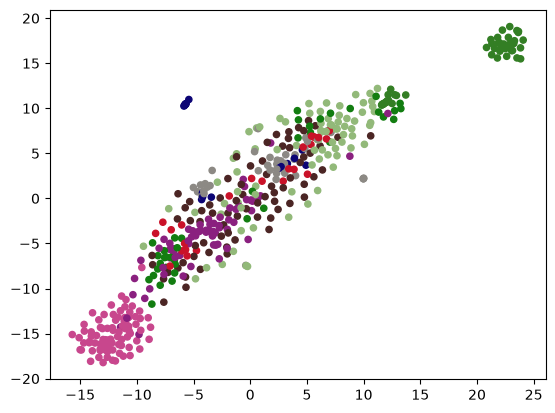

In [14]:
from sklearn.manifold import TSNE

random_select = np.random.choice(X_test_raw.shape[0], 500, replace=False)
X = X_test_raw[random_select,:,:,:].reshape(500,X_train.shape[1]).astype('float')/255.0

tic = time.time()
Y = TSNE(n_components=2, perplexity=25.0).fit_transform(X)
print("it takes {} seconds".format(time.time()-tic))

## visualize tSNE of original data
labels = y_test[random_select]
colors = np.random.rand(num_classes,3)
color_labels = [colors[int(i)] for i in labels.tolist()]
plt.scatter(Y[:,0], Y[:,1], 20, color_labels)
plt.show()

### t-SNE of Data After Two Hidden Layers

Visualize the t-SNE of data after going through MLP. In the visualization result, you should find that the t-SNE of the original data points are rather jumbled up. However, visualization of data after the trained two-layer networks are clearly separated into multiple clusters in a 2D panel.

In [15]:
# Define MLP model
model = MLP(input_dim=X_train.shape[1], hidden_dims=[100], num_classes=num_classes, reg=0.1, weight_scale=1e-3)

num_epoch = 10
batch_size = 200
lr = 1e-3
verbose = False
train_acc_hist, val_acc_hist = train(model, X_train, y_train, X_val, y_val, 
                  num_epoch=num_epoch, batch_size=batch_size, learning_rate=lr, verbose=verbose)
test(model, X_test, y_test)

number of batches for training: 449
epoch 1: valid acc = 0.39724110355857656, new learning rate = 0.00095
epoch 2: valid acc = 0.4643142742902839, new learning rate = 0.0009025
epoch 3: valid acc = 0.5362854858056777, new learning rate = 0.000857375
epoch 4: valid acc = 0.552578968412635, new learning rate = 0.0008145062499999999
epoch 5: valid acc = 0.5729708116753298, new learning rate = 0.0007737809374999998
epoch 6: valid acc = 0.5826669332267094, new learning rate = 0.0007350918906249997
epoch 7: valid acc = 0.5928628548580568, new learning rate = 0.0006983372960937497
epoch 8: valid acc = 0.5785685725709716, new learning rate = 0.0006634204312890621
epoch 9: valid acc = 0.5957616953218713, new learning rate = 0.000630249409724609
epoch 10: valid acc = 0.607157137145142, new learning rate = 0.0005987369392383785
test acc: 0.5853760445682451


np.float64(0.5853760445682451)

<span style="color:red"><strong>TODO</strong></span>: Visualize data that is passed through the MLP model defined above using t-SNE. 

it takes 1.7161967754364014 seconds


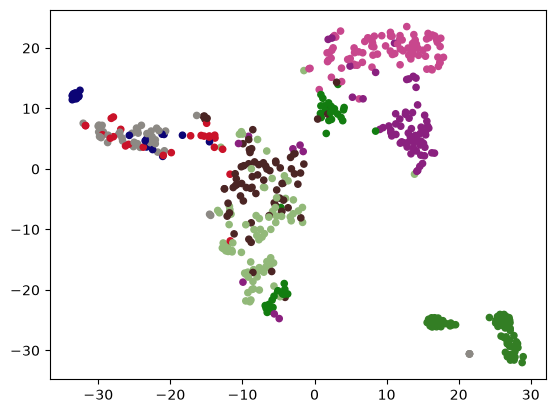

In [16]:
# Visualize tSNE 2D representation of data after two hidden layers
#############################################################################
#                          START OF YOUR CODE                               #
# Hint: See tSNE visualization of original data
#############################################################################

X_mlp = model.forward(X_test[random_select])

tic = time.time()
Y = TSNE(n_components=2, perplexity=25.0).fit_transform(X_mlp)
print("it takes {} seconds".format(time.time()-tic))

plt.scatter(Y[:,0], Y[:,1], 20, color_labels)
plt.show()

#############################################################################
#                          END OF YOUR CODE                                 #
#############################################################################

<span style="color:red"><strong>TODO</strong></span>: Try tuning the parameters of t-SNE. Do visualization of the new t-SNE of the data.

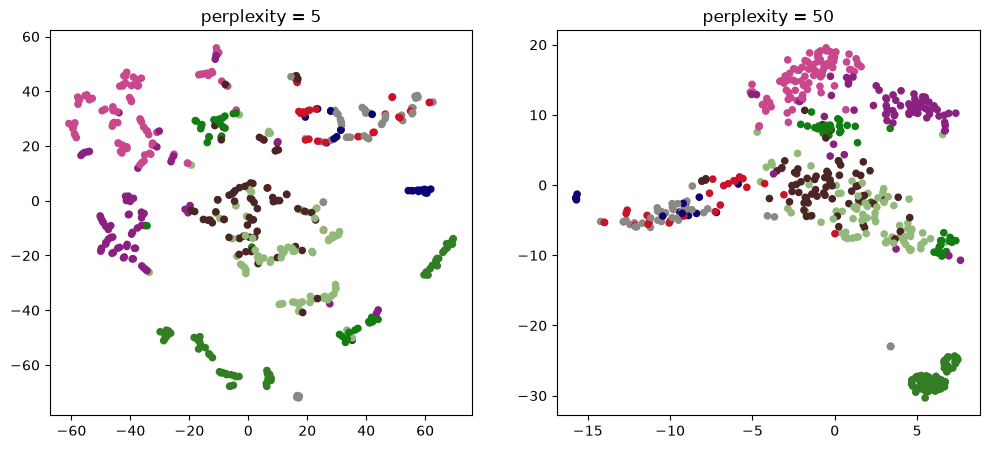

it takes 3.927565813064575 seconds


In [17]:
# Tune the parameter, show the results.
# run t-SNE
tic = time.time()

#############################################################################
#                          START OF YOUR CODE                               #
#############################################################################

perplexities = [5, 50]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, perp in zip(axes, perplexities):
    Y = TSNE(n_components=2, perplexity=perp, early_exaggeration=20.0, init='pca').fit_transform(X_mlp)
    ax.scatter(Y[:,0], Y[:,1], 20, color_labels)
    ax.set_title('perplexity = {}'.format(perp))
plt.show()

#############################################################################
#                          END OF YOUR CODE                                 #
#############################################################################


print("it takes {} seconds".format(time.time()-tic))

## Part 4: Comparing Activation Functions


<span style="color:red"><strong>TODO</strong></span>: Train an MLP with two different hidden-layer activation functions (ReLU and Tanh, using the `activation` parameter you implemented in `MLP`) on PathMNIST, keeping all other hyperparameters identical. Plot the validation accuracy of each over training, and tabulate the final train/val/test accuracy for both, as a deliverable comparing the two activations.



In [18]:
# Train two MLPs with identical architecture/hyperparameters, differing only
# in hidden-layer activation function, to compare their accuracy directly.

#############################################################################
#                          START OF YOUR CODE                               #
#############################################################################

from utils.layer_funcs import check_accuracy

results = {}
for act in ['relu', 'tanh']:
    print(act)
    mlp = MLP(input_dim=X_train.shape[1], hidden_dims=[200, 100], num_classes=num_classes,
              reg=0.1, weight_scale=1e-3, activation=act)
    train_hist, val_hist = train(
        mlp, X_train, y_train, X_val, y_val,
        num_epoch=10, batch_size=128, learning_rate=1e-4,
        optim='momentum', momentum=0.9, verbose=False
    )
    results[act] = {
        'model': mlp,
        'val_hist': val_hist,
        'train_acc': check_accuracy(mlp.predict(X_train), y_train),
        'val_acc': val_hist[-1],
        'test_acc': test(mlp, X_test, y_test),
    }

#############################################################################
#                          END OF YOUR CODE                                 #
#############################################################################

relu
number of batches for training: 703
epoch 1: valid acc = 0.22041183526589364, new learning rate = 9.5e-05
epoch 2: valid acc = 0.226609356257497, new learning rate = 9.025e-05


KeyboardInterrupt: 

In [ ]:
############################################################################
# TODO: Plot the validation accuracy of both activation functions over    #
# epochs, and tabulate their final train/val/test accuracy.               #
############################################################################
############################################################################
#                         START OF YOUR CODE                               #
############################################################################

for act, r in results.items():
    plt.plot(range(1, len(r['val_hist']) + 1), r['val_hist'], label=act)
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.legend()
plt.show()

print('{:<10}{:>10}{:>10}{:>10}'.format('activation', 'train', 'val', 'test'))
for act, r in results.items():
    print('{:<10}{:>10.4f}{:>10.4f}{:>10.4f}'.format(act, r['train_acc'], r['val_acc'], r['test_acc']))

############################################################################
#                          END OF YOUR CODE                                #
############################################################################

## Part 5: Confusion Matrix — Compared Against Task 1's Baseline

<span style="color:red"><strong>TODO</strong></span>: Generate a confusion matrix for your trained FC network (MLP) on the PathMNIST test set, the same way you did for the Softmax classifier in Task 1. Compute its overall test accuracy.

In [ ]:
############################################################################
# TODO: Generate a confusion matrix for your FC network (MLP) on the      #
# PathMNIST test set, and compute its overall test accuracy.              #
############################################################################
############################################################################
#                         START OF YOUR CODE                               #
############################################################################

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

label_map = [
    'adipose', 'background', 'debris', 'lymphocytes', 'mucus',
    'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma',
    'colorectal adenocarcinoma epithelium',
]

fc_model = results['relu']['model']
y_test_pred = fc_model.predict(X_test)
print('test accuracy: %f' % (np.mean(y_test == y_test_pred), ))

cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_map)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation='vertical')
plt.show()

############################################################################
#                          END OF YOUR CODE                                #
############################################################################

In [ ]:
### Question: Did the FC network improve per-class performance evenly, or did it just get better at majority classes?

Compare the confusion matrix above to Task 1's baseline Softmax classifier confusion matrix. The FC (MLP) network achieves higher overall accuracy than the linear Softmax baseline. Looking at the per-class breakdown in both confusion matrices, did every class improve roughly equally, or did the accuracy gains concentrate in certain (e.g. majority) classes while others remained weak?

   Your answer: **[fill in here]**